# DSCI 552 — Homework 7

**Name:** Gina Mao  
**GitHub Username:** ruoxuanm116  
**USC ID:** 8885483334

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_score, recall_score, roc_auc_score, roc_curve,
                             silhouette_score)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### 1(a) Load the Anuran Calls (MFCCs) data and choose 70% randomly as the training set

In [2]:
DATA_PATH = "../data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv"
df = pd.read_csv(DATA_PATH)

FEATURES = [c for c in df.columns if c.startswith("MFCCs_")]
LABELS = ["Family", "Genus", "Species"]

X = df[FEATURES].values
Y = df[LABELS].values

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, train_size=0.7, random_state=RANDOM_STATE, shuffle=True)

print("Full data:", df.shape)
print("Training set:", X_train.shape, " Test set:", X_test.shape)
df.head()

Full data: (7195, 26)
Training set: (5036, 22)  Test set: (2159, 22)


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


In [3]:
for lab in LABELS:
    print(f"--- {lab} ({df[lab].nunique()} classes) ---")
    print(df[lab].value_counts().to_string(), "\n")

--- Family (4 classes) ---
Family
Leptodactylidae    4420
Hylidae            2165
Dendrobatidae       542
Bufonidae            68 

--- Genus (8 classes) ---
Genus
Adenomera        4150
Hypsiboas        1593
Ameerega          542
Dendropsophus     310
Leptodactylus     270
Scinax            148
Osteocephalus     114
Rhinella           68 

--- Species (10 classes) ---
Species
AdenomeraHylaedactylus    3478
HypsiboasCordobae         1121
AdenomeraAndre             672
Ameeregatrivittata         542
HypsiboasCinerascens       472
HylaMinuta                 310
LeptodactylusFuscus        270
ScinaxRuber                148
OsteocephalusOophagus      114
Rhinellagranulosa           68 



The classes are clearly **imbalanced** (e.g., *Leptodactylidae* has 4420 rows while *Bufonidae* has 68), which is why 1(b)iv asks for SMOTE.

### 1(b)i Exact match and Hamming score / loss

Each instance has $L=3$ labels (Family, Genus, Species). For $n$ instances with true label vector $Y_i$ and predicted vector $\hat Y_i$:

* **Exact match ratio (subset accuracy)** — the fraction of instances for which *all* labels are predicted correctly:
$$\text{ExactMatch} = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\hat Y_i = Y_i\right]$$
It is the strictest metric: a prediction with 2 of 3 labels correct counts as completely wrong.

* **Hamming loss** — the fraction of individual labels that are predicted wrong:
$$\text{HammingLoss} = \frac{1}{nL}\sum_{i=1}^{n}\sum_{j=1}^{L} \mathbb{1}\left[\hat y_{ij} \neq y_{ij}\right]$$
Lower is better. The **Hamming distance** of an instance is the number of wrong labels, $\sum_j \mathbb{1}[\hat y_{ij}\ne y_{ij}] \in \{0,1,2,3\}$, so Hamming loss = average Hamming distance / $L$.

* **Hamming score** — in this multi-class/multi-output setting (every instance has exactly one class per label), the Hamming score is the fraction of correctly predicted labels: $\text{HammingScore} = 1-\text{HammingLoss}$.
  (Sorower's survey also defines a set-based Hamming score $\frac{1}{n}\sum_i \frac{|Y_i\cap \hat Y_i|}{|Y_i\cup \hat Y_i|}$ for binary-indicator labels; with one class per label that version behaves monotonically the same way, so we report $1-$HammingLoss.)

In [4]:
def exact_match(Y_true, Y_pred):
    Y_true, Y_pred = np.asarray(Y_true), np.asarray(Y_pred)
    return np.mean(np.all(Y_true == Y_pred, axis=1))

def hamming_distance(Y_true, Y_pred):
    # average number of wrong labels per instance
    Y_true, Y_pred = np.asarray(Y_true), np.asarray(Y_pred)
    return np.mean(np.sum(Y_true != Y_pred, axis=1))

def hamming_loss_ml(Y_true, Y_pred):
    Y_true, Y_pred = np.asarray(Y_true), np.asarray(Y_pred)
    return np.mean(Y_true != Y_pred)

def hamming_score_ml(Y_true, Y_pred):
    return 1 - hamming_loss_ml(Y_true, Y_pred)

def summarize(Y_true, Y_pred, name):
    row = {"Model": name,
           "Exact match": exact_match(Y_true, Y_pred),
           "Hamming loss": hamming_loss_ml(Y_true, Y_pred),
           "Hamming score": hamming_score_ml(Y_true, Y_pred)}
    for j, lab in enumerate(LABELS):
        row[f"{lab} acc"] = accuracy_score(Y_true[:, j], Y_pred[:, j])
        row[f"{lab} macro-F1"] = f1_score(Y_true[:, j], Y_pred[:, j], average="macro")
    return row

results = []   # collects test-set metrics of all models
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

### 1(b)ii Gaussian-kernel SVM, one-vs-all, one classifier per label (binary relevance)

Notation: scikit-learn's RBF kernel is $K(x,x')=\exp(-\gamma\|x-x'\|^2)$, so the kernel width $\sigma$ corresponds to $\gamma = \frac{1}{2\sigma^2}$. The penalty weight is `C`.
One-vs-all is enforced with `OneVsRestClassifier(SVC(kernel="rbf"))` (plain `SVC` would use one-vs-one).

**Choosing the parameter ranges (footnote 1).** First train on the whole training set with very small and very large values and keep the region where the training accuracy stays above ~70%. The probe below uses the hardest label (Species, 10 classes).

In [5]:
def rbf_ovr(C=1.0, sigma=1.0):
    return OneVsRestClassifier(SVC(kernel="rbf", C=C, gamma=1 / (2 * sigma ** 2)))

y_sp = Y_train[:, 2]
X_train_std_probe = StandardScaler().fit_transform(X_train)

probe = {}
for name, XX, sigmas in [("raw", X_train, [0.2, 0.5, 1, 2, 3, 5]),
                         ("standardized", X_train_std_probe, [0.5, 1, 3, 5, 10, 20])]:
    tab = pd.DataFrame(index=[1e-3, 1e-1, 1e1, 1e3, 1e5], columns=sigmas, dtype=float)
    for C in tab.index:
        for s in sigmas:
            tab.loc[C, s] = rbf_ovr(C, s).fit(XX, y_sp).score(XX, y_sp)
    tab.index.name, tab.columns.name = "C", "sigma"
    probe[name] = tab
    print(f"Training accuracy (Species), {name} attributes:")
    display(tab.round(3))

Training accuracy (Species), raw attributes:


sigma,0.2,0.5,1.0,2.0,3.0,5.0
C,,,,,,
0.001,0.626,0.651,0.546,0.535,0.533,0.534
0.100,0.995,0.968,0.916,0.870,0.840,0.723
10.000,1.000,1.000,0.996,0.976,0.955,0.935
1000.000,1.000,1.000,1.000,0.999,0.996,0.988
100000.000,1.000,1.000,1.000,1.000,1.000,1.000


Training accuracy (Species), standardized attributes:


sigma,0.5,1.0,3.0,5.0,10.0,20.0
C,,,,,,
0.001,0.586,0.601,0.653,0.561,0.526,0.518
0.100,0.600,0.998,0.975,0.939,0.891,0.856
10.000,1.000,1.000,1.000,0.999,0.988,0.958
1000.000,1.000,1.000,1.000,1.000,1.000,0.997
100000.000,1.000,1.000,1.000,1.000,1.000,1.000


From the probe: with $C=10^{-3}$ the accuracy falls below 70% for every $\sigma$, while from $C\approx 10^{-1}$ upward the accuracy is above 70% for the moderate widths. Very small widths (σ ≤ 0.1 for raw data) memorise the training data and are also very slow, and very large widths underfit at small $C$.
So the CV grids are: $\log_{10} C \in \{-1,0,1,2,3,4\}$ (log increments), and linear increments for σ:

* raw attributes: σ ∈ {0.25, 0.5, 0.75, 1.0, 1.5, 2.0}
* standardized attributes (distances are ~4× larger after standardizing): σ ∈ {1, 2, 3, 4, 6, 8}

Each label gets its own 10-fold stratified CV grid search.

In [6]:
C_GRID = [1e-1, 1e0, 1e1, 1e2, 1e3, 1e4]
SIGMA_RAW = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
SIGMA_STD = [1, 2, 3, 4, 6, 8]

def tune_rbf(standardize, sigmas):
    steps = [("scaler", StandardScaler())] if standardize else []
    steps.append(("svm", OneVsRestClassifier(SVC(kernel="rbf"))))
    grid = {"svm__estimator__C": C_GRID,
            "svm__estimator__gamma": [1 / (2 * s ** 2) for s in sigmas]}
    models, rows = [], []
    Y_pred = np.empty_like(Y_test)
    for j, lab in enumerate(LABELS):
        t0 = time.time()
        gs = GridSearchCV(Pipeline(steps), grid, cv=cv10, scoring="accuracy", n_jobs=-1)
        gs.fit(X_train, Y_train[:, j])
        Y_pred[:, j] = gs.predict(X_test)
        g = gs.best_params_["svm__estimator__gamma"]
        rows.append({"Label": lab, "best C": gs.best_params_["svm__estimator__C"],
                     "best sigma": np.sqrt(1 / (2 * g)), "best gamma": g,
                     "10-fold CV acc": gs.best_score_,
                     "test acc": accuracy_score(Y_test[:, j], Y_pred[:, j]),
                     "time (s)": round(time.time() - t0, 1)})
        models.append(gs)
    return models, Y_pred, pd.DataFrame(rows)

rbf_raw_models, Y_pred_rbf_raw, tab_rbf_raw = tune_rbf(False, SIGMA_RAW)
print("Gaussian-kernel SVM, RAW attributes")
display(tab_rbf_raw)

Gaussian-kernel SVM, RAW attributes


,Label,best C,best sigma,best gamma,10-fold CV acc,test acc,time (s)
0,Family,100.0,0.5,2.0,0.992652,0.995368,60.6
1,Genus,10.0,0.5,2.0,0.991462,0.990736,81.7
2,Species,100.0,0.5,2.0,0.991066,0.991200,91.6


In [7]:
rbf_std_models, Y_pred_rbf_std, tab_rbf_std = tune_rbf(True, SIGMA_STD)
print("Gaussian-kernel SVM, STANDARDIZED attributes")
display(tab_rbf_std)

Gaussian-kernel SVM, STANDARDIZED attributes


,Label,best C,best sigma,best gamma,10-fold CV acc,test acc,time (s)
0,Family,100.0,3.0,0.055556,0.992056,0.993979,75.2
1,Genus,10.0,3.0,0.055556,0.991858,0.987957,125.6
2,Species,10.0,3.0,0.055556,0.990867,0.987494,150.6


In [8]:
results.append(summarize(Y_test, Y_pred_rbf_raw, "RBF SVM (raw)"))
results.append(summarize(Y_test, Y_pred_rbf_std, "RBF SVM (standardized)"))
pd.DataFrame(results).set_index("Model").round(4)

,Exact match,Hamming loss,Hamming score,Family acc,Family macro-F1,Genus acc,Genus macro-F1,Species acc,Species macro-F1
Model,,,,,,,,,
RBF SVM (raw),0.9889,0.0076,0.9924,0.9954,0.9857,0.9907,0.9706,0.9912,0.9749
RBF SVM (standardized),0.9866,0.0102,0.9898,0.9940,0.9862,0.9880,0.9653,0.9875,0.9656


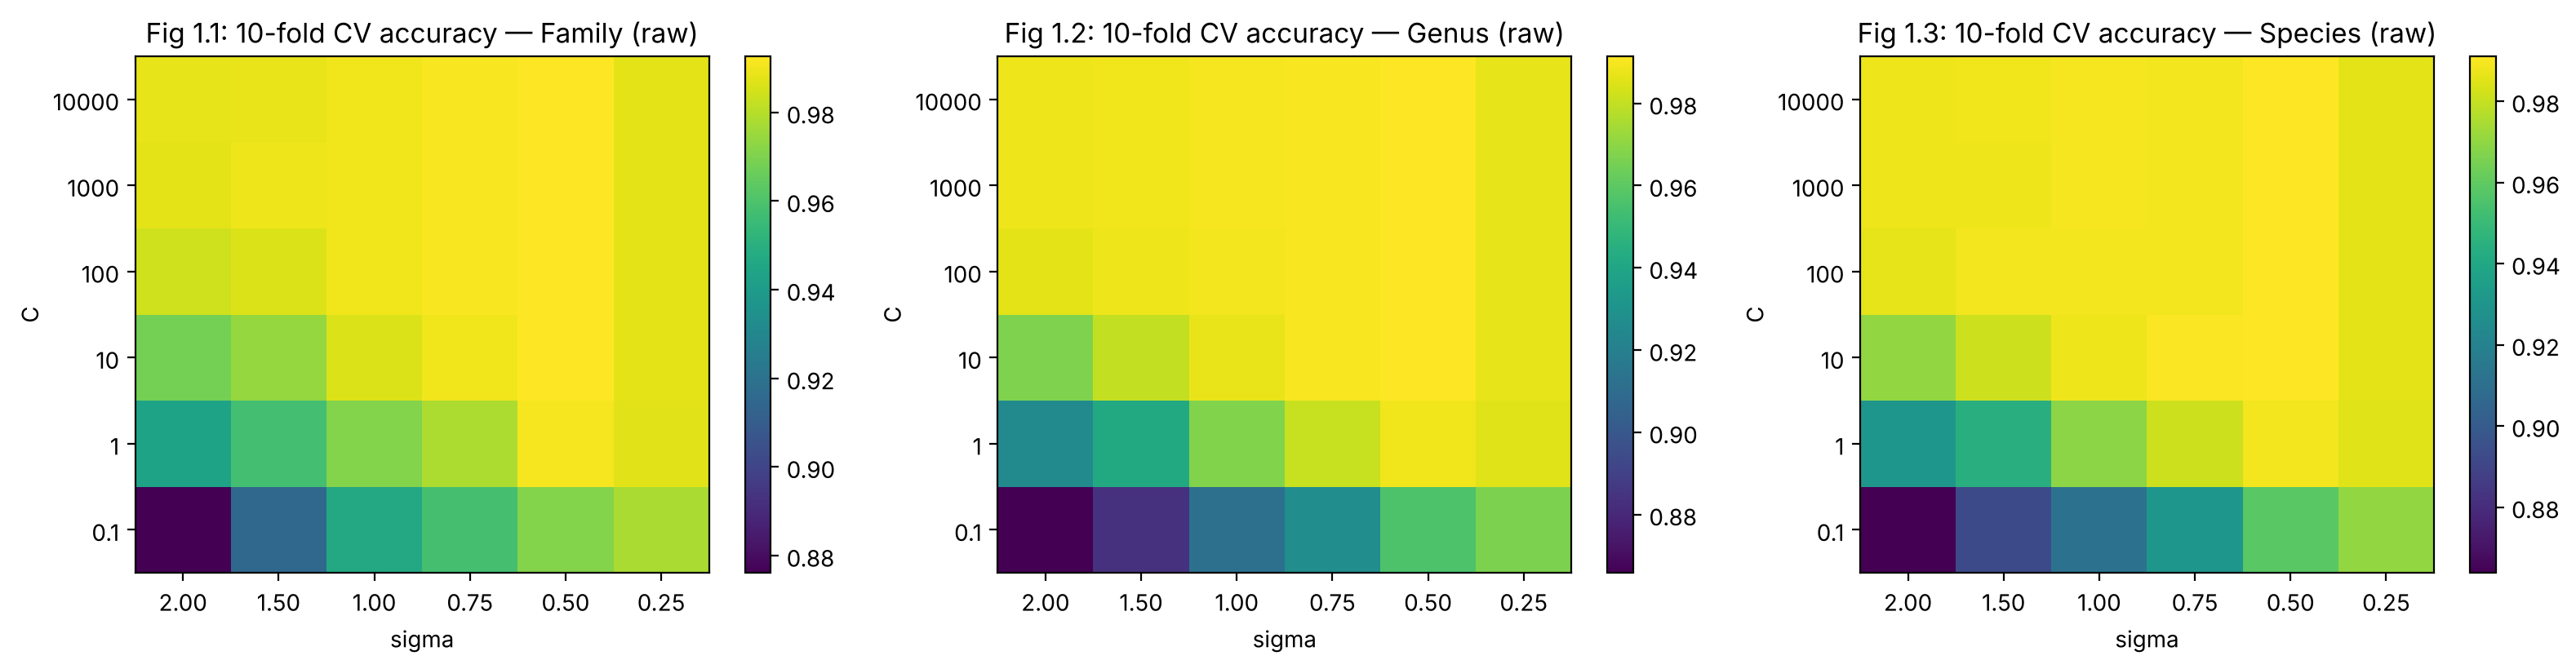

In [9]:
# CV accuracy surface for each label (raw attributes) - helps check the grid is wide enough
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, gs, lab in zip(axes, rbf_raw_models, LABELS):
    cvr = pd.DataFrame(gs.cv_results_)
    piv = cvr.pivot_table(index="param_svm__estimator__C", columns="param_svm__estimator__gamma",
                          values="mean_test_score")
    im = ax.imshow(piv.values, cmap="viridis", aspect="auto", origin="lower")
    ax.set_xticks(range(len(piv.columns)))
    ax.set_xticklabels([f"{np.sqrt(1/(2*g)):.2f}" for g in piv.columns])
    ax.set_yticks(range(len(piv.index)))
    ax.set_yticklabels([f"{c:g}" for c in piv.index])
    ax.set_xlabel("sigma"); ax.set_ylabel("C")
    ax.set_title(f"Fig 1.{LABELS.index(lab)+1}: 10-fold CV accuracy — {lab} (raw)")
    fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

**Results of 1(b)ii.** 10-fold CV chose σ = 0.5 (γ = 2) with C = 100 / 10 / 100 for Family / Genus / Species on raw attributes, and σ = 3 (γ ≈ 0.056) with C = 100 / 10 / 10 on standardized attributes. The chosen values are inside the grids (not on the edges), so the ranges were wide enough (see Fig 1).

| Test set | Exact match | Hamming loss | Hamming score |
|---|---|---|---|
| RBF SVM, raw | 0.9889 | 0.0076 | 0.9924 |
| RBF SVM, standardized | 0.9866 | 0.0102 | 0.9898 |

Both versions are excellent (≈99% per-label accuracy). The raw attributes are slightly better, which makes sense because the MFCCs are already normalized to [−1, 1]; standardizing rescales the low-variance coefficients up and adds a little noise.

### 1(b)iii L1-penalized SVM (linear kernel), standardized attributes

`LinearSVC(penalty="l1", loss="squared_hinge", dual=False)` is used; it is one-vs-rest for multi-class problems by default. Attributes are standardized inside the pipeline (so the scaler is fit only on the training folds).
Range check: the training accuracy on Species is computed over $C\in[10^{-4},10^{3}]$ to find where it stays above 70%.

In [10]:
def l1_svm(C=1.0):
    return LinearSVC(penalty="l1", loss="squared_hinge", dual=False, C=C, max_iter=10000)

probe_l1 = []
for C in [1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3]:
    m = Pipeline([("scaler", StandardScaler()), ("svm", l1_svm(C))]).fit(X_train, y_sp)
    probe_l1.append({"C": C, "train acc (Species)": m.score(X_train, y_sp)})
pd.DataFrame(probe_l1)

,C,train acc (Species)
0,0.0001,0.089754
1,0.0010,0.801231
2,0.0100,0.920770
3,0.1000,0.953932
4,1.0000,0.963066
5,10.0000,0.964654
6,100.0000,0.964853
7,1000.0000,0.964853


The training accuracy is below 70% only at the smallest $C$ and saturates for large $C$, so the CV grid is $\log_{10}C \in \{-3,-2.5,\dots,2\}$ (11 values).

In [11]:
C_GRID_L1 = list(np.logspace(-3, 2, 11))

def tune_l1(use_smote):
    if use_smote:
        pipe = ImbPipeline([("scaler", StandardScaler()),
                            ("smote", SMOTE(random_state=RANDOM_STATE)),
                            ("svm", l1_svm())])
    else:
        pipe = Pipeline([("scaler", StandardScaler()), ("svm", l1_svm())])
    models, rows = [], []
    Y_pred = np.empty_like(Y_test)
    for j, lab in enumerate(LABELS):
        t0 = time.time()
        gs = GridSearchCV(pipe, {"svm__C": C_GRID_L1}, cv=cv10, scoring="accuracy", n_jobs=-1)
        gs.fit(X_train, Y_train[:, j])
        Y_pred[:, j] = gs.predict(X_test)
        coef = gs.best_estimator_.named_steps["svm"].coef_
        rows.append({"Label": lab, "best C": gs.best_params_["svm__C"],
                     "10-fold CV acc": gs.best_score_,
                     "test acc": accuracy_score(Y_test[:, j], Y_pred[:, j]),
                     "test balanced acc": balanced_accuracy_score(Y_test[:, j], Y_pred[:, j]),
                     "zero coefs": f"{np.sum(coef == 0)}/{coef.size}",
                     "time (s)": round(time.time() - t0, 1)})
        models.append(gs)
    return models, Y_pred, pd.DataFrame(rows)

l1_models, Y_pred_l1, tab_l1 = tune_l1(use_smote=False)
print("L1-penalized linear SVM, standardized attributes")
display(tab_l1)
results.append(summarize(Y_test, Y_pred_l1, "L1 linear SVM"))

L1-penalized linear SVM, standardized attributes


,Label,best C,10-fold CV acc,test acc,test balanced acc,zero coefs,time (s)
0,Family,10.0,0.941223,0.928208,0.690223,0/88,31.0
1,Genus,100.0,0.951551,0.941640,0.769036,0/176,67.4
2,Species,10.0,0.960682,0.959240,0.894759,0/220,76.5


### 1(b)iv L1-penalized SVM + SMOTE

SMOTE creates synthetic minority-class samples by interpolating between a minority point and its nearest minority neighbours, until every class has as many samples as the majority class.
It is placed **inside** an `imblearn` pipeline (scaler → SMOTE → SVM), so oversampling happens only on the training folds during CV and never touches the validation fold or the test set.

In [12]:
l1s_models, Y_pred_l1s, tab_l1s = tune_l1(use_smote=True)
print("L1-penalized linear SVM + SMOTE, standardized attributes")
display(tab_l1s)
results.append(summarize(Y_test, Y_pred_l1s, "L1 linear SVM + SMOTE"))

L1-penalized linear SVM + SMOTE, standardized attributes


,Label,best C,10-fold CV acc,test acc,test balanced acc,zero coefs,time (s)
0,Family,3.162278,0.923156,0.909217,0.913069,2/88,204.7
1,Genus,1.000000,0.912837,0.902270,0.916202,1/176,800.2
2,Species,3.162278,0.958103,0.957851,0.927611,0/220,1044.4


In [13]:
# Per-class recall on the test set: does SMOTE help the small classes?
for j, lab in enumerate(LABELS):
    classes = np.unique(Y_train[:, j])
    rec = pd.DataFrame({
        "test support": pd.Series(Y_test[:, j]).value_counts().reindex(classes).values,
        "recall L1": recall_score(Y_test[:, j], Y_pred_l1[:, j], labels=classes, average=None),
        "recall L1+SMOTE": recall_score(Y_test[:, j], Y_pred_l1s[:, j], labels=classes, average=None),
        "recall RBF (raw)": recall_score(Y_test[:, j], Y_pred_rbf_raw[:, j], labels=classes, average=None),
    }, index=classes).sort_values("test support")
    print(f"=== {lab} ===")
    display(rec.round(3))

=== Family ===


,test support,recall L1,recall L1+SMOTE,recall RBF (raw)
Bufonidae,27,0.000,0.889,0.926
Dendrobatidae,162,0.895,0.975,0.994
Hylidae,623,0.904,0.867,0.997
Leptodactylidae,1347,0.962,0.921,0.996


=== Genus ===


,test support,recall L1,recall L1+SMOTE,recall RBF (raw)
Rhinella,27,0.259,0.926,0.889
Osteocephalus,34,0.500,0.882,0.882
Scinax,37,0.892,0.973,0.973
Dendropsophus,84,0.714,0.893,0.964
Leptodactylus,96,0.906,0.896,0.979
Ameerega,162,0.932,0.957,1.000
Hypsiboas,468,0.970,0.912,0.996
Adenomera,1251,0.978,0.890,0.996


=== Species ===


,test support,recall L1,recall L1+SMOTE,recall RBF (raw)
Rhinellagranulosa,27,0.889,0.926,0.926
OsteocephalusOophagus,34,0.647,0.882,0.882
ScinaxRuber,37,0.946,0.946,0.973
HylaMinuta,84,0.774,0.893,0.976
LeptodactylusFuscus,96,0.896,0.906,0.979
HypsiboasCinerascens,135,0.963,0.963,0.978
Ameeregatrivittata,162,0.944,0.944,1.000
AdenomeraAndre,220,0.914,0.877,0.982
HypsiboasCordobae,333,0.976,0.943,0.997
AdenomeraHylaedactylus,1031,0.999,0.995,1.000


,Exact match,Hamming loss,Hamming score,Family acc,Family macro-F1,Genus acc,Genus macro-F1,Species acc,Species macro-F1
Model,,,,,,,,,
RBF SVM (raw),0.9889,0.0076,0.9924,0.9954,0.9857,0.9907,0.9706,0.9912,0.9749
RBF SVM (standardized),0.9866,0.0102,0.9898,0.9940,0.9862,0.9880,0.9653,0.9875,0.9656
L1 linear SVM,0.9125,0.0570,0.9430,0.9282,0.6828,0.9416,0.8091,0.9592,0.9060
L1 linear SVM + SMOTE,0.8536,0.0769,0.9231,0.9092,0.7947,0.9023,0.8024,0.9579,0.9035


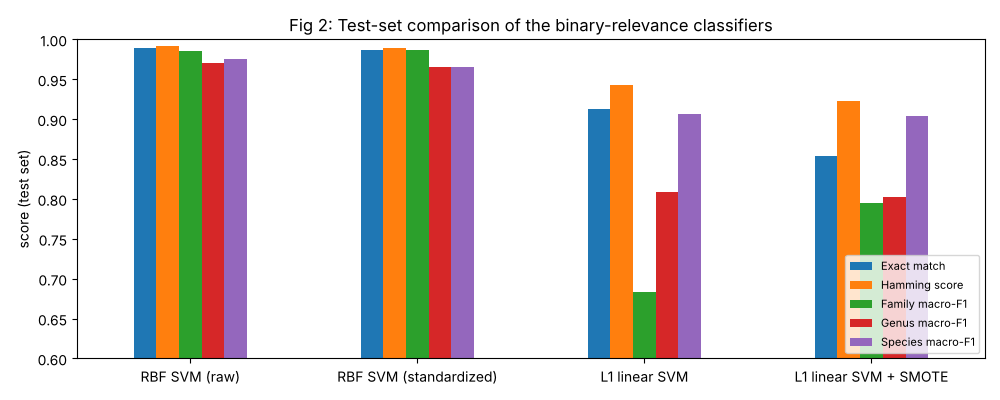

In [14]:
summary_df = pd.DataFrame(results).set_index("Model")
display(summary_df.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
summary_df[["Exact match", "Hamming score", "Family macro-F1", "Genus macro-F1", "Species macro-F1"]].plot.bar(ax=ax)
ax.set_ylim(0.6, 1.0); ax.set_ylabel("score (test set)")
ax.set_title("Fig 2: Test-set comparison of the binary-relevance classifiers")
ax.legend(loc="lower right", fontsize=8); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Conclusions about the classifiers (1(b)ii–iv).**

| Test set | Exact match | Hamming loss | Hamming score |
|---|---|---|---|
| RBF SVM, raw | **0.9889** | **0.0076** | **0.9924** |
| RBF SVM, standardized | 0.9866 | 0.0102 | 0.9898 |
| L1 linear SVM | 0.9125 | 0.0570 | 0.9430 |
| L1 linear SVM + SMOTE | 0.8536 | 0.0769 | 0.9231 |

1. **The Gaussian-kernel SVM is clearly the best model.** The classes are not linearly separable in the 22-dimensional MFCC space, so the non-linear kernel wins by about 7.6 points of exact match over the linear L1 SVM.
2. **The L1 penalty did not make the model sparse here.** The CV-chosen C is fairly large (10–100), so almost no coefficients are zero. All 22 MFCCs carry useful information.
3. **Class imbalance hurts the plain L1 SVM on the small classes.** For example, it never predicts *Bufonidae* (recall 0 for Family) and gets only 26% recall on genus *Rhinella*. That is why its Family macro-F1 is only 0.68 even though its accuracy is 0.93.
4. **SMOTE fixes the minority classes but costs overall accuracy.** With SMOTE, *Bufonidae* recall goes from 0 to 0.89 and *Rhinella* from 0.26 to 0.93. Balanced accuracy rises from 0.69 to 0.91 (Family) and from 0.77 to 0.92 (Genus), and Family macro-F1 goes from 0.68 to 0.79. The cost: the linear boundary now gives up some majority-class points, so plain accuracy, exact match (0.91 → 0.85) and Hamming score (0.943 → 0.923) go down. Whether SMOTE is "better" depends on the goal. If every species matters equally, SMOTE is preferable. If overall accuracy is what counts, it is not.
5. Because exact match needs all three labels right, it is always the lowest metric. The gap between exact match and Hamming score is largest for the L1 models, which often get one label of the triplet wrong.

### 1(b)v (Extra Practice) Classifier Chain

Binary relevance ignores the dependence between labels (a species fixes its genus and family). A **classifier chain** trains the classifiers in order Family → Genus → Species, and each classifier in the chain also receives the (one-hot) predictions of the previous labels as extra features.
To avoid the training-time features being "too perfect", the chain features for the training set are the **out-of-fold predictions** (`cross_val_predict`, 10 folds) of the earlier classifiers; at test time the earlier classifiers' test predictions are used. Each link is an RBF one-vs-all SVM with the hyper-parameters chosen in 1(b)ii (raw attributes).

In [15]:
chain_train_feats, chain_test_feats = X_train.copy(), X_test.copy()
Y_pred_chain = np.empty_like(Y_test)
for j, lab in enumerate(LABELS):
    bp = rbf_raw_models[j].best_params_
    clf = OneVsRestClassifier(SVC(kernel="rbf", C=bp["svm__estimator__C"], gamma=bp["svm__estimator__gamma"]))
    clf.fit(chain_train_feats, Y_train[:, j])
    Y_pred_chain[:, j] = clf.predict(chain_test_feats)
    if j < len(LABELS) - 1:
        oof = cross_val_predict(clf, chain_train_feats, Y_train[:, j], cv=cv10, n_jobs=-1)
        enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(Y_train[:, [j]])
        chain_train_feats = np.hstack([chain_train_feats, enc.transform(oof.reshape(-1, 1))])
        chain_test_feats = np.hstack([chain_test_feats, enc.transform(Y_pred_chain[:, [j]])])

results.append(summarize(Y_test, Y_pred_chain, "Classifier chain (RBF)"))
pd.DataFrame(results).set_index("Model").round(4)

,Exact match,Hamming loss,Hamming score,Family acc,Family macro-F1,Genus acc,Genus macro-F1,Species acc,Species macro-F1
Model,,,,,,,,,
RBF SVM (raw),0.9889,0.0076,0.9924,0.9954,0.9857,0.9907,0.9706,0.9912,0.9749
RBF SVM (standardized),0.9866,0.0102,0.9898,0.9940,0.9862,0.9880,0.9653,0.9875,0.9656
L1 linear SVM,0.9125,0.0570,0.9430,0.9282,0.6828,0.9416,0.8091,0.9592,0.9060
L1 linear SVM + SMOTE,0.8536,0.0769,0.9231,0.9092,0.7947,0.9023,0.8024,0.9579,0.9035
Classifier chain (RBF),0.9880,0.0086,0.9914,0.9954,0.9857,0.9898,0.9707,0.9889,0.9689


In [16]:
# How often are the predicted (Family, Genus, Species) triplets taxonomically consistent?
valid = set(map(tuple, df[LABELS].drop_duplicates().values))
for name, P in [("RBF SVM (raw)", Y_pred_rbf_raw), ("L1 linear SVM", Y_pred_l1),
                ("L1 + SMOTE", Y_pred_l1s), ("Classifier chain", Y_pred_chain)]:
    print(f"{name:20s}: {np.mean([tuple(r) in valid for r in P]):.4f} of predicted triplets exist in the data")

RBF SVM (raw)       : 0.9944 of predicted triplets exist in the data
L1 linear SVM       : 0.9440 of predicted triplets exist in the data
L1 + SMOTE          : 0.8782 of predicted triplets exist in the data
Classifier chain    : 0.9949 of predicted triplets exist in the data


**Classifier chain result.** The chain (exact match 0.9880, Hamming score 0.9914) performs essentially the same as binary relevance with the same RBF SVMs (0.9889 / 0.9924). It produces slightly more taxonomically consistent triplets (99.49% vs 99.44%). Each RBF SVM is already ~99% accurate on its own, so the earlier labels add little new information to the later ones. Any small gain from using the label dependence is offset by errors that pass down the chain.

### 1(b)vi (Extra Practice) Confusion matrices, precision, recall, ROC and AUC for multi-label classification

For a multi-label problem these are computed **per label** (each label here is a multi-class problem), and then averaged:

* **Confusion matrix**: one $K\times K$ matrix per label (or, in the binary-indicator view, one $2\times2$ matrix per class of each label).
* **Precision / recall**: per class, then averaged — *macro* (unweighted mean of classes, sensitive to small classes), *micro* (pool all TP/FP/FN — equals accuracy for single-label multi-class), or *weighted* (by support). The example-based versions from Sorower's survey are $\frac{1}{n}\sum_i\frac{|Y_i\cap\hat Y_i|}{|\hat Y_i|}$ and $\frac{1}{n}\sum_i\frac{|Y_i\cap\hat Y_i|}{|Y_i|}$; since every instance has exactly 3 true and 3 predicted labels, both equal the Hamming score.
* **ROC / AUC**: binarize each label one-vs-rest and use the SVM decision values as scores; one ROC curve per class, plus micro/macro averaged AUC. For the whole multi-label problem we stack all 4+8+10 = 22 binary indicator columns and compute the micro-averaged AUC.

These are shown for the Gaussian-kernel SVM (raw) and the L1 SVM + SMOTE.

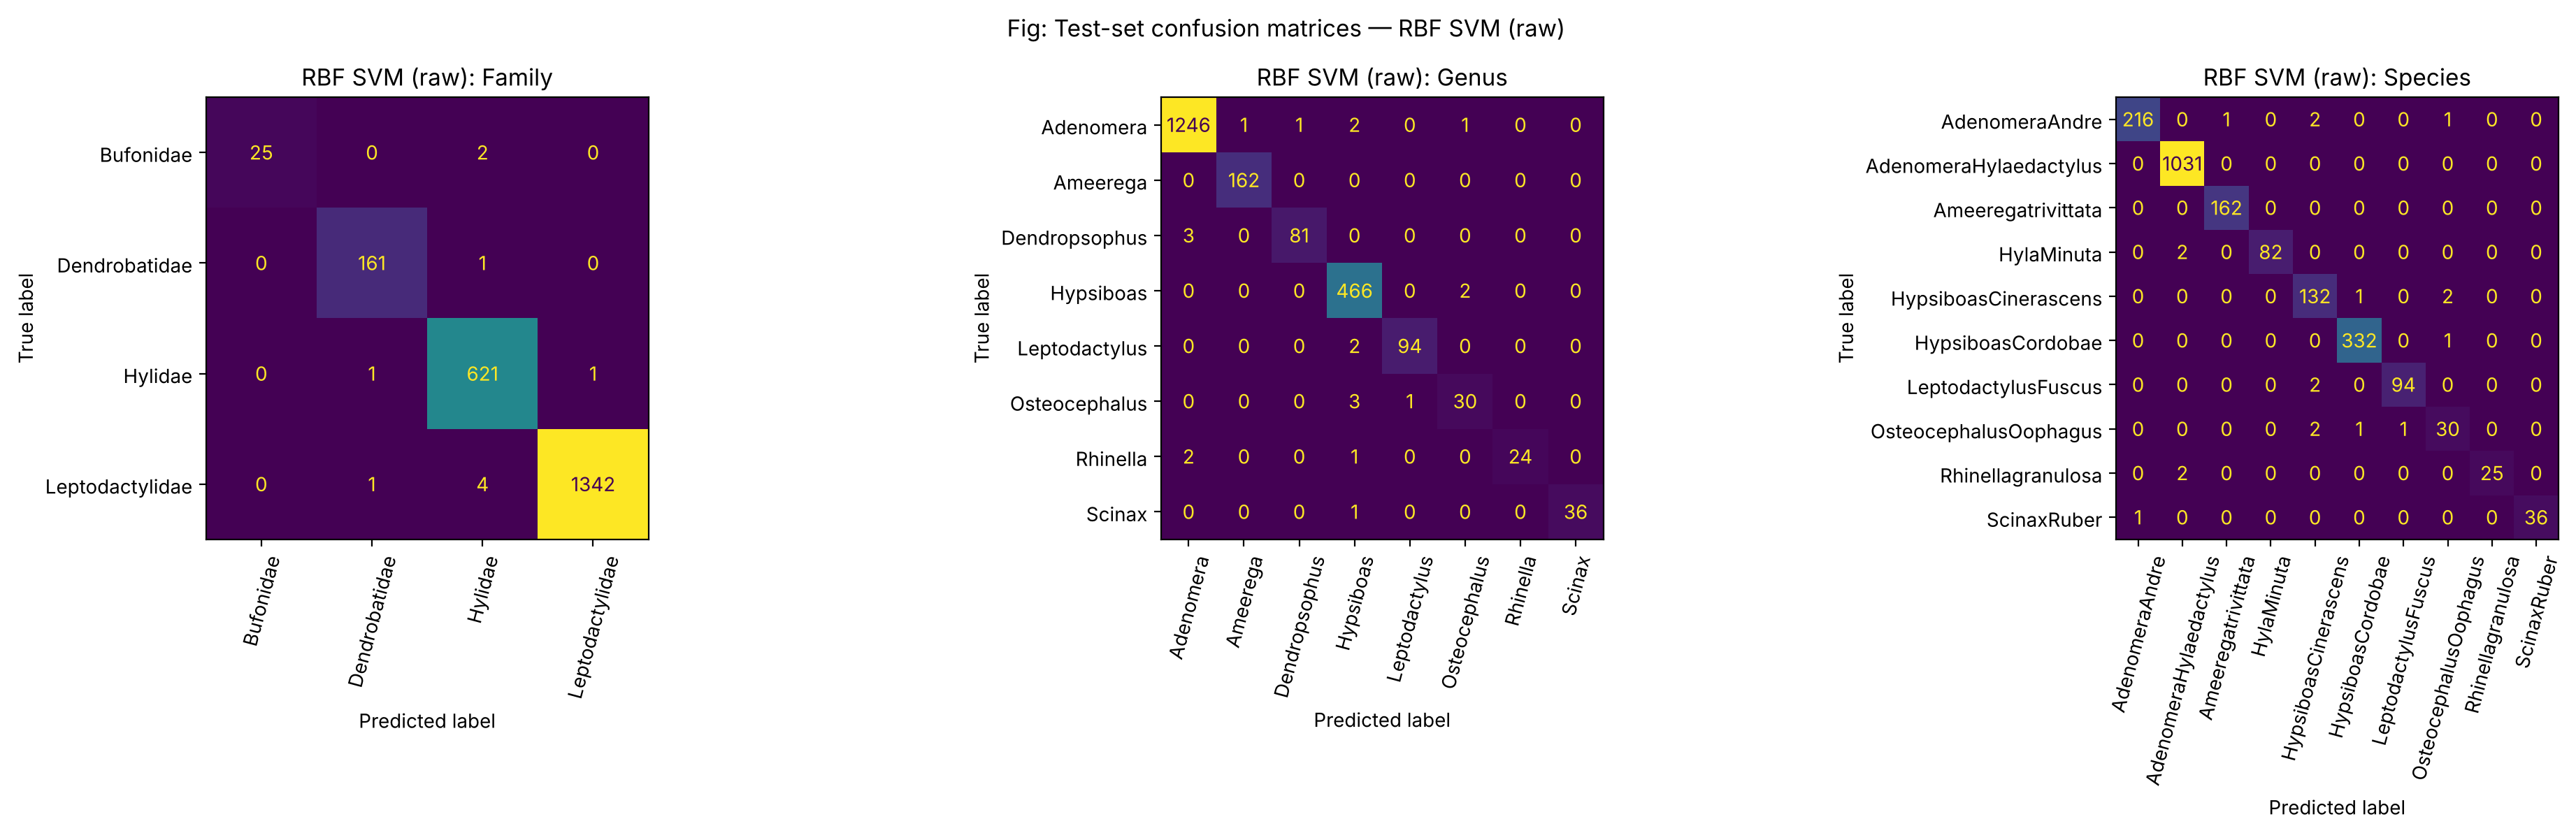

Overall multi-label micro-AUC (all 22 indicator columns): 0.9994


,macro precision,macro recall,micro precision,micro recall,macro AUC,micro AUC
Label,,,,,,
Family,0.9940,0.9782,0.9954,0.9954,0.9993,0.9997
Genus,0.9822,0.9599,0.9907,0.9907,0.9975,0.9994
Species,0.9808,0.9693,0.9912,0.9912,0.9978,0.9991


In [17]:
def per_label_report(models, Y_pred, name):
    rows, Ybin_all, S_all = [], [], []
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    for j, (lab, m) in enumerate(zip(LABELS, models)):
        classes = m.best_estimator_.classes_
        Ybin = label_binarize(Y_test[:, j], classes=classes)
        S = m.decision_function(X_test)
        if Ybin.shape[1] == 1:      # (not the case here, all labels have >2 classes)
            Ybin, S = np.hstack([1 - Ybin, Ybin]), np.vstack([-S, S]).T
        Ybin_all.append(Ybin); S_all.append(S)
        rows.append({"Label": lab,
                     "macro precision": precision_score(Y_test[:, j], Y_pred[:, j], average="macro"),
                     "macro recall": recall_score(Y_test[:, j], Y_pred[:, j], average="macro"),
                     "micro precision": precision_score(Y_test[:, j], Y_pred[:, j], average="micro"),
                     "micro recall": recall_score(Y_test[:, j], Y_pred[:, j], average="micro"),
                     "macro AUC": roc_auc_score(Ybin, S, average="macro"),
                     "micro AUC": roc_auc_score(Ybin, S, average="micro")})
        cm = confusion_matrix(Y_test[:, j], Y_pred[:, j], labels=classes)
        ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=axes[j], xticks_rotation=75, colorbar=False)
        axes[j].set_title(f"{name}: {lab}")
    fig.suptitle(f"Fig: Test-set confusion matrices — {name}"); plt.tight_layout(); plt.show()
    Yb, Sa = np.hstack(Ybin_all), np.hstack(S_all)
    print(f"Overall multi-label micro-AUC (all {Yb.shape[1]} indicator columns): {roc_auc_score(Yb, Sa, average='micro'):.4f}")
    display(pd.DataFrame(rows).set_index("Label").round(4))
    return Ybin_all, S_all

roc_rbf = per_label_report(rbf_raw_models, Y_pred_rbf_raw, "RBF SVM (raw)")

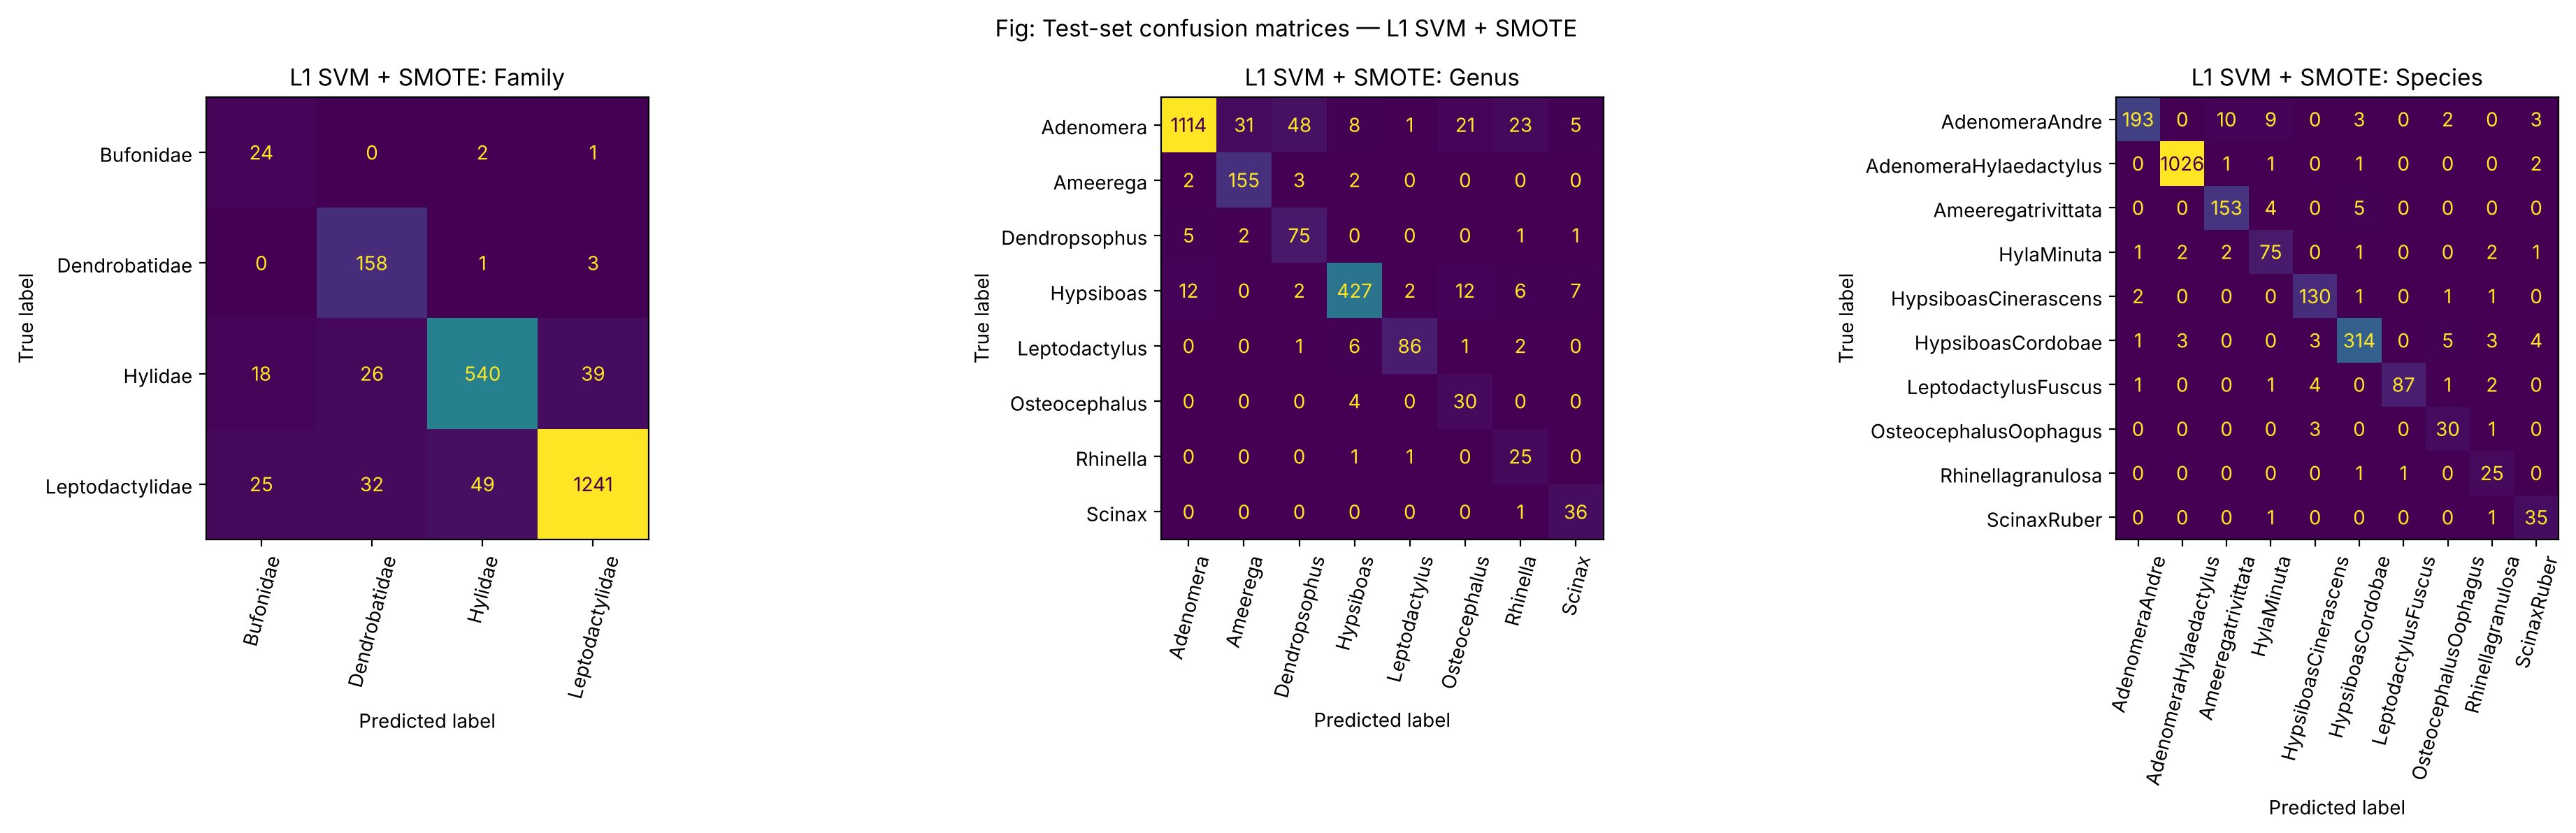

Overall multi-label micro-AUC (all 22 indicator columns): 0.9866


,macro precision,macro recall,micro precision,micro recall,macro AUC,micro AUC
Label,,,,,,
Family,0.7421,0.9131,0.9092,0.9092,0.9678,0.9763
Genus,0.7415,0.9162,0.9023,0.9023,0.9770,0.9832
Species,0.8857,0.9276,0.9579,0.9579,0.9839,0.9921


In [18]:
roc_l1s = per_label_report(l1s_models, Y_pred_l1s, "L1 SVM + SMOTE")

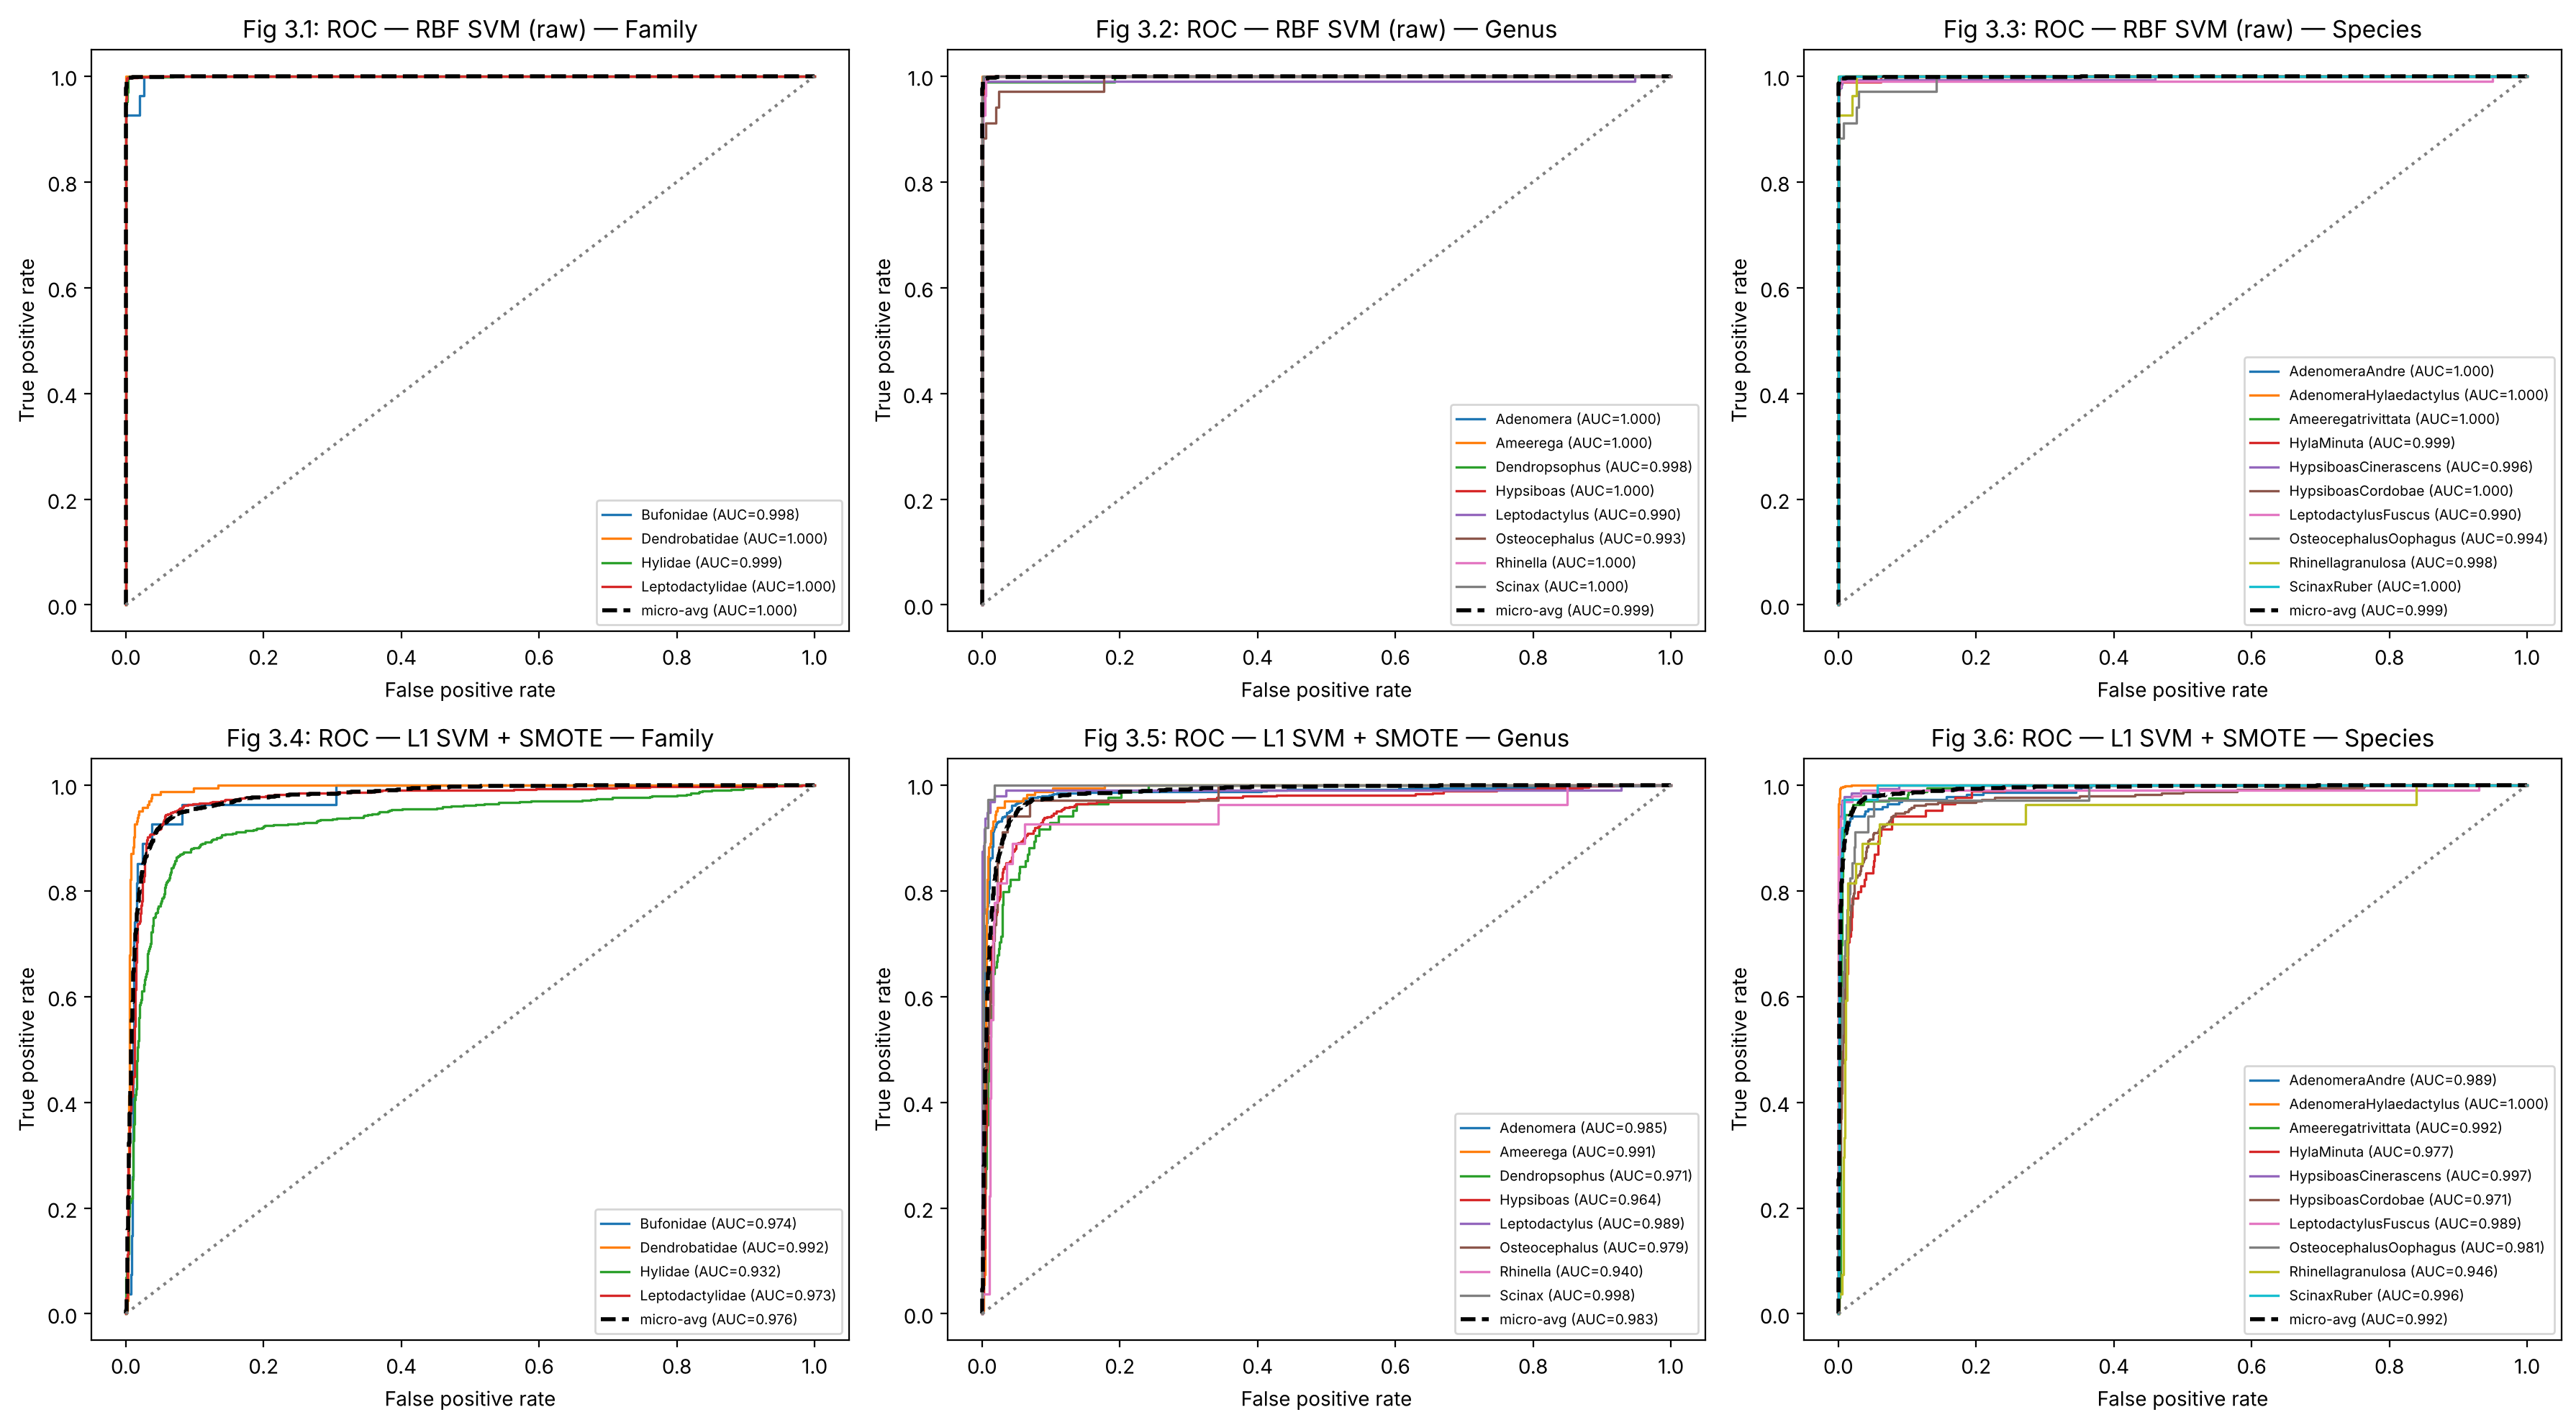

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for r, (name, (Yb_list, S_list), models) in enumerate([("RBF SVM (raw)", roc_rbf, rbf_raw_models),
                                                       ("L1 SVM + SMOTE", roc_l1s, l1s_models)]):
    for j, lab in enumerate(LABELS):
        ax = axes[r, j]
        Yb, S = Yb_list[j], S_list[j]
        for k, cls in enumerate(models[j].best_estimator_.classes_):
            fpr, tpr, _ = roc_curve(Yb[:, k], S[:, k])
            ax.plot(fpr, tpr, lw=1.2, label=f"{cls} (AUC={roc_auc_score(Yb[:, k], S[:, k]):.3f})")
        fpr, tpr, _ = roc_curve(Yb.ravel(), S.ravel())
        ax.plot(fpr, tpr, "k--", lw=2, label=f"micro-avg (AUC={roc_auc_score(Yb, S, average='micro'):.3f})")
        ax.plot([0, 1], [0, 1], ":", color="grey")
        ax.set_title(f"Fig 3.{3*r+j+1}: ROC — {name} — {lab}")
        ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
        ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

**Monte-Carlo simulation**: the whole procedure (a)–(c) is repeated 50 times with different random seeds (different k-means initialisations, including the choice of $k$).

* **(a)** k-means is run on the **whole** data set (no train/test split). $k$ is chosen automatically by the **Silhouette** method: for $k = 2,\dots,50$ fit k-means and pick the $k$ with the largest average silhouette width. ($k=1$ is not possible for the silhouette, which needs at least two clusters; with one cluster every point gets the same majority triplet, which is clearly worse.) To keep 50 × 49 fits feasible, k-means uses `n_init=3` and the silhouette is estimated on a random sample of 3000 points.
* **(b)** In each cluster the majority Family, majority Genus and majority Species are found from the true labels.
* **(c)** Each point gets its cluster's majority triplet; the Hamming distance, Hamming score and Hamming loss between the true and assigned triplets are computed.

In [20]:
X_all = df[FEATURES].values
Y_all = df[LABELS].values
K_RANGE = range(2, 51)

def choose_k(seed):
    sil = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=3, random_state=seed).fit(X_all)
        sil.append(silhouette_score(X_all, km.labels_, sample_size=3000, random_state=seed))
    return list(K_RANGE)[int(np.argmax(sil))], sil

def majority_triplets(cluster_labels):
    out = {}
    for c in np.unique(cluster_labels):
        sub = df.loc[cluster_labels == c, LABELS]
        out[c] = tuple(sub[lab].value_counts().idxmax() for lab in LABELS)
    return out

def run_once(seed, verbose=False):
    k, sil = choose_k(seed)
    km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X_all)
    maj = majority_triplets(km.labels_)
    Y_assigned = np.array([maj[c] for c in km.labels_])
    res = {"seed": seed, "k": k,
           "Hamming distance": hamming_distance(Y_all, Y_assigned),
           "Hamming score": hamming_score_ml(Y_all, Y_assigned),
           "Hamming loss": hamming_loss_ml(Y_all, Y_assigned),
           "Exact match": exact_match(Y_all, Y_assigned)}
    if verbose:
        return res, sil, km, maj
    return res

#### One run in detail (seed 0): silhouette curve, majority triplets per cluster

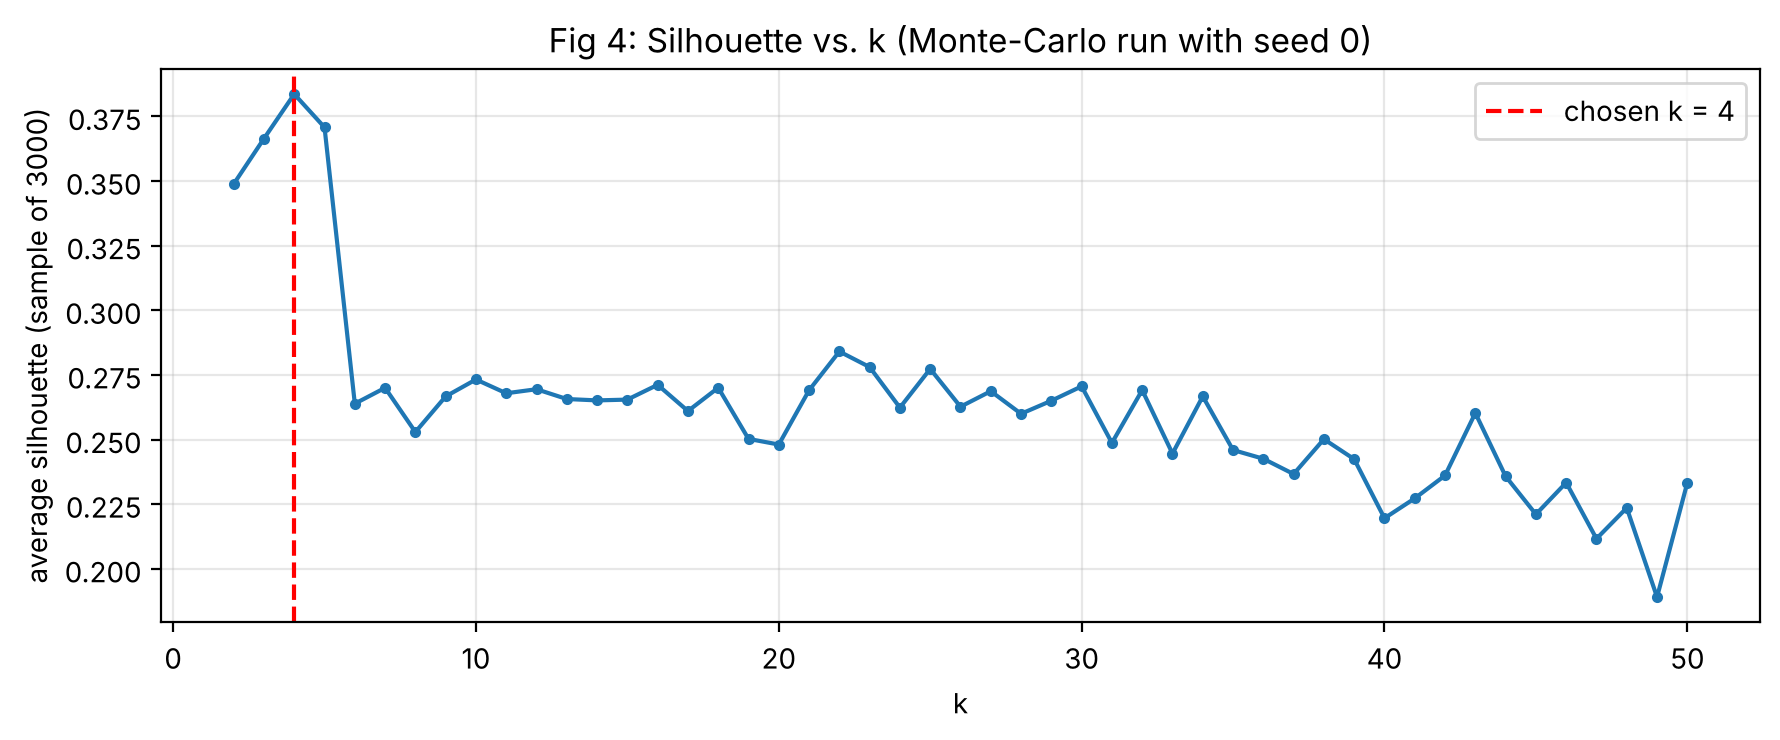

,Cluster,Size,Majority Family,Majority Genus,Majority Species
0,0,3568,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,1982,Hylidae,Hypsiboas,HypsiboasCordobae
2,2,1031,Dendrobatidae,Ameerega,Ameeregatrivittata
3,3,614,Hylidae,Hypsiboas,HypsiboasCinerascens


{'seed': 0, 'k': 4, 'Hamming distance': np.float64(0.66726893676164), 'Hamming score': np.float64(0.7775770210794533), 'Hamming loss': np.float64(0.2224229789205467), 'Exact match': np.float64(0.7555246699096595)}


In [21]:
res0, sil0, km0, maj0 = run_once(0, verbose=True)

plt.figure(figsize=(9, 3.8))
plt.plot(list(K_RANGE), sil0, "o-", ms=3)
plt.axvline(res0["k"], color="r", ls="--", label=f"chosen k = {res0['k']}")
plt.xlabel("k"); plt.ylabel("average silhouette (sample of 3000)")
plt.title("Fig 4: Silhouette vs. k (Monte-Carlo run with seed 0)"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

maj_tab = pd.DataFrame([(c, (km0.labels_ == c).sum(), *maj0[c]) for c in sorted(maj0)],
                       columns=["Cluster", "Size", "Majority Family", "Majority Genus", "Majority Species"])
display(maj_tab)
print(res0)

In [22]:
t0 = time.time()
mc = pd.DataFrame([run_once(seed) for seed in range(50)])
print(f"50 Monte-Carlo runs finished in {time.time() - t0:.0f} s")
display(mc.head(10))
print("Chosen k over the 50 runs:", mc["k"].value_counts().to_dict())

50 Monte-Carlo runs finished in 363 s


,seed,k,Hamming distance,Hamming score,Hamming loss,Exact match
0,0,4,0.667269,0.777577,0.222423,0.755525
1,1,4,0.667269,0.777577,0.222423,0.755525
2,2,4,0.735372,0.754876,0.245124,0.682974
3,3,4,0.667269,0.777577,0.222423,0.755525
4,4,5,0.503266,0.832245,0.167755,0.809868
5,5,4,0.667269,0.777577,0.222423,0.755525
6,6,4,0.667269,0.777577,0.222423,0.755525
7,7,4,0.667269,0.777577,0.222423,0.755525
8,8,6,0.504517,0.831828,0.168172,0.810007
9,9,4,0.667269,0.777577,0.222423,0.755525


Chosen k over the 50 runs: {4: 42, 6: 4, 5: 3, 3: 1}


In [23]:
mc_summary = mc[["Hamming distance", "Hamming score", "Hamming loss", "Exact match"]].agg(["mean", "std"]).T
mc_summary

,mean,std
Hamming distance,0.653504,0.070277
Hamming score,0.782165,0.023426
Hamming loss,0.217835,0.023426
Exact match,0.755900,0.032441


**Results of the 50 Monte-Carlo runs (Q2).**

| Metric (whole data set) | Mean | Std. dev. |
|---|---|---|
| **Hamming distance** (avg. # wrong labels out of 3) | **0.6535** | **0.0703** |
| Hamming score | 0.7822 | 0.0234 |
| Hamming loss | 0.2178 | 0.0234 |
| Exact match (extra) | 0.7559 | 0.0324 |

* The silhouette method chose **k = 4** in 42 of the 50 runs (k = 6: 4 runs, k = 5: 3 runs, k = 3: 1 run). k = 4 equals the number of families.
* In the k = 4 solution the clusters' majority triplets are (Leptodactylidae, Adenomera, AdenomeraHylaedactylus), (Hylidae, Hypsiboas, HypsiboasCordobae), (Dendrobatidae, Ameerega, Ameeregatrivittata) and (Hylidae, Hypsiboas, HypsiboasCinerascens). With only 4 clusters, at most 4 of the 10 species can ever be assigned. That is why the unsupervised labelling gets on average ~0.65 of the 3 labels wrong per frog call (Hamming loss ≈ 0.22). The supervised SVMs reach a Hamming loss below 0.01.
* The runs with k = 5 or 6 have a lower Hamming distance (≈ 0.50), because more clusters can represent more species. The silhouette criterion rewards well-separated clusters, not label purity.

## 3. ISLR 12.6.2

Dissimilarity matrix of four observations:

$$\begin{bmatrix} & 0.3 & 0.4 & 0.7\\ 0.3 & & 0.5 & 0.8\\ 0.4 & 0.5 & & 0.45\\ 0.7 & 0.8 & 0.45 & \end{bmatrix}$$

In [24]:
D = np.array([[0.00, 0.30, 0.40, 0.70],
              [0.30, 0.00, 0.50, 0.80],
              [0.40, 0.50, 0.00, 0.45],
              [0.70, 0.80, 0.45, 0.00]])
d = squareform(D)
Z_complete = linkage(d, method="complete")
Z_single = linkage(d, method="single")
print("Complete linkage merges [cluster i, cluster j, height, size]:\n", Z_complete)
print("Single linkage merges:\n", Z_single)

Complete linkage merges [cluster i, cluster j, height, size]:
 [[0.   1.   0.3  2.  ]
 [2.   3.   0.45 2.  ]
 [4.   5.   0.8  4.  ]]
Single linkage merges:
 [[0.   1.   0.3  2.  ]
 [2.   4.   0.4  3.  ]
 [3.   5.   0.45 4.  ]]


### 3(a) Complete linkage

* The smallest dissimilarity is 0.3 → fuse **{1,2}** at height **0.3**.
* New dissimilarities (maximum): d({1,2},3)=max(0.4,0.5)=0.5, d({1,2},4)=max(0.7,0.8)=0.8, d(3,4)=0.45 → fuse **{3,4}** at **0.45**.
* d({1,2},{3,4}) = max(0.4,0.5,0.7,0.8) = 0.8 → fuse everything at **0.8**.

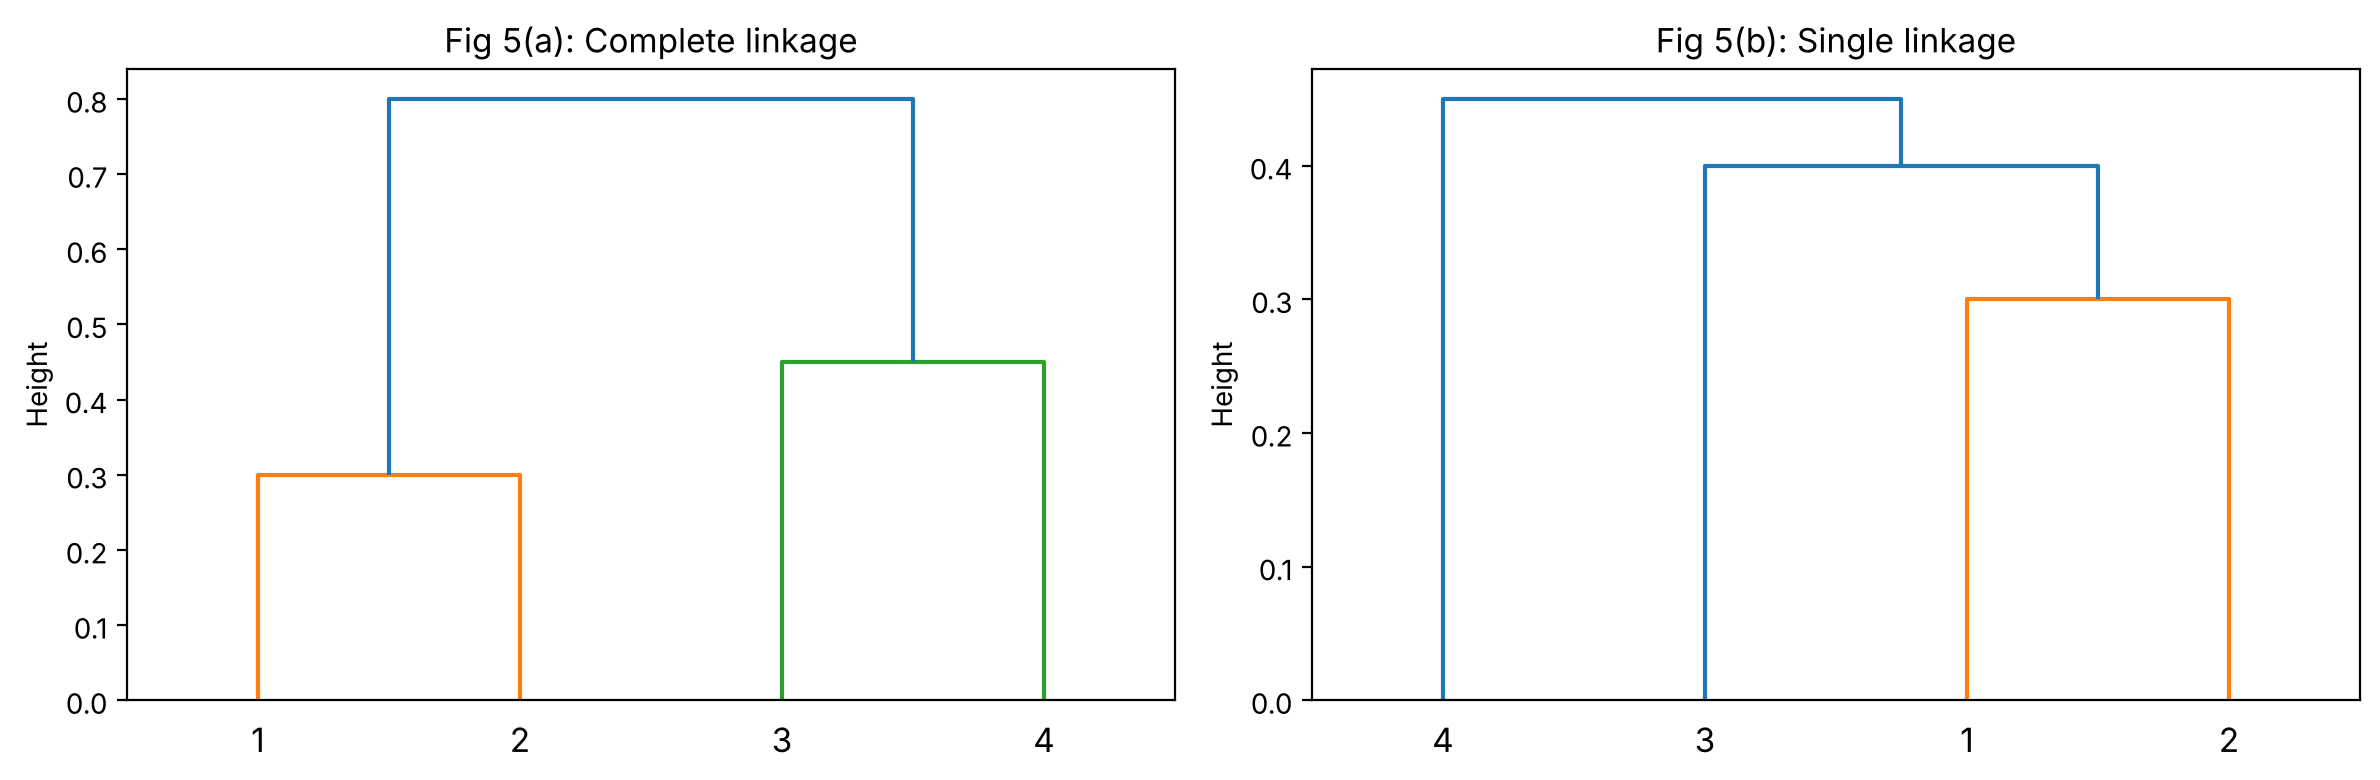

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dendrogram(Z_complete, labels=[1, 2, 3, 4], ax=axes[0])
axes[0].set_title("Fig 5(a): Complete linkage"); axes[0].set_ylabel("Height")
dendrogram(Z_single, labels=[1, 2, 3, 4], ax=axes[1])
axes[1].set_title("Fig 5(b): Single linkage"); axes[1].set_ylabel("Height")
plt.tight_layout(); plt.show()

### 3(b) Single linkage

* Fuse **{1,2}** at **0.3**.
* New dissimilarities (minimum): d({1,2},3)=min(0.4,0.5)=0.4, d({1,2},4)=min(0.7,0.8)=0.7, d(3,4)=0.45 → observation **3 joins {1,2}** at **0.4**.
* d({1,2,3},4)=min(0.7,0.8,0.45)=0.45 → **4 joins** at **0.45**.

(Dendrogram: Fig 5(b) above.)

### 3(c) Cut the complete-linkage dendrogram into two clusters
Cutting between heights 0.45 and 0.8 gives **{1, 2}** and **{3, 4}**.

### 3(d) Cut the single-linkage dendrogram into two clusters
Cutting between heights 0.4 and 0.45 gives **{1, 2, 3}** and **{4}**.

In [26]:
print("(c) complete linkage, 2 clusters:", fcluster(Z_complete, 2, criterion="maxclust"))
print("(d) single linkage,   2 clusters:", fcluster(Z_single, 2, criterion="maxclust"))

(c) complete linkage, 2 clusters: [1 1 2 2]
(d) single linkage,   2 clusters: [1 1 1 2]


### 3(e) An equivalent dendrogram with two or more leaves repositioned
At any fusion the two branches can be swapped without changing the meaning of the dendrogram. Swapping the branches at every fusion of the complete-linkage dendrogram gives the leaf order **4, 3, 2, 1** — the same fusions ({1,2} at 0.3, {3,4} at 0.45, all at 0.8), so the meaning is identical. Below, the two children of every merge in the linkage matrix are swapped, which only flips the drawing.

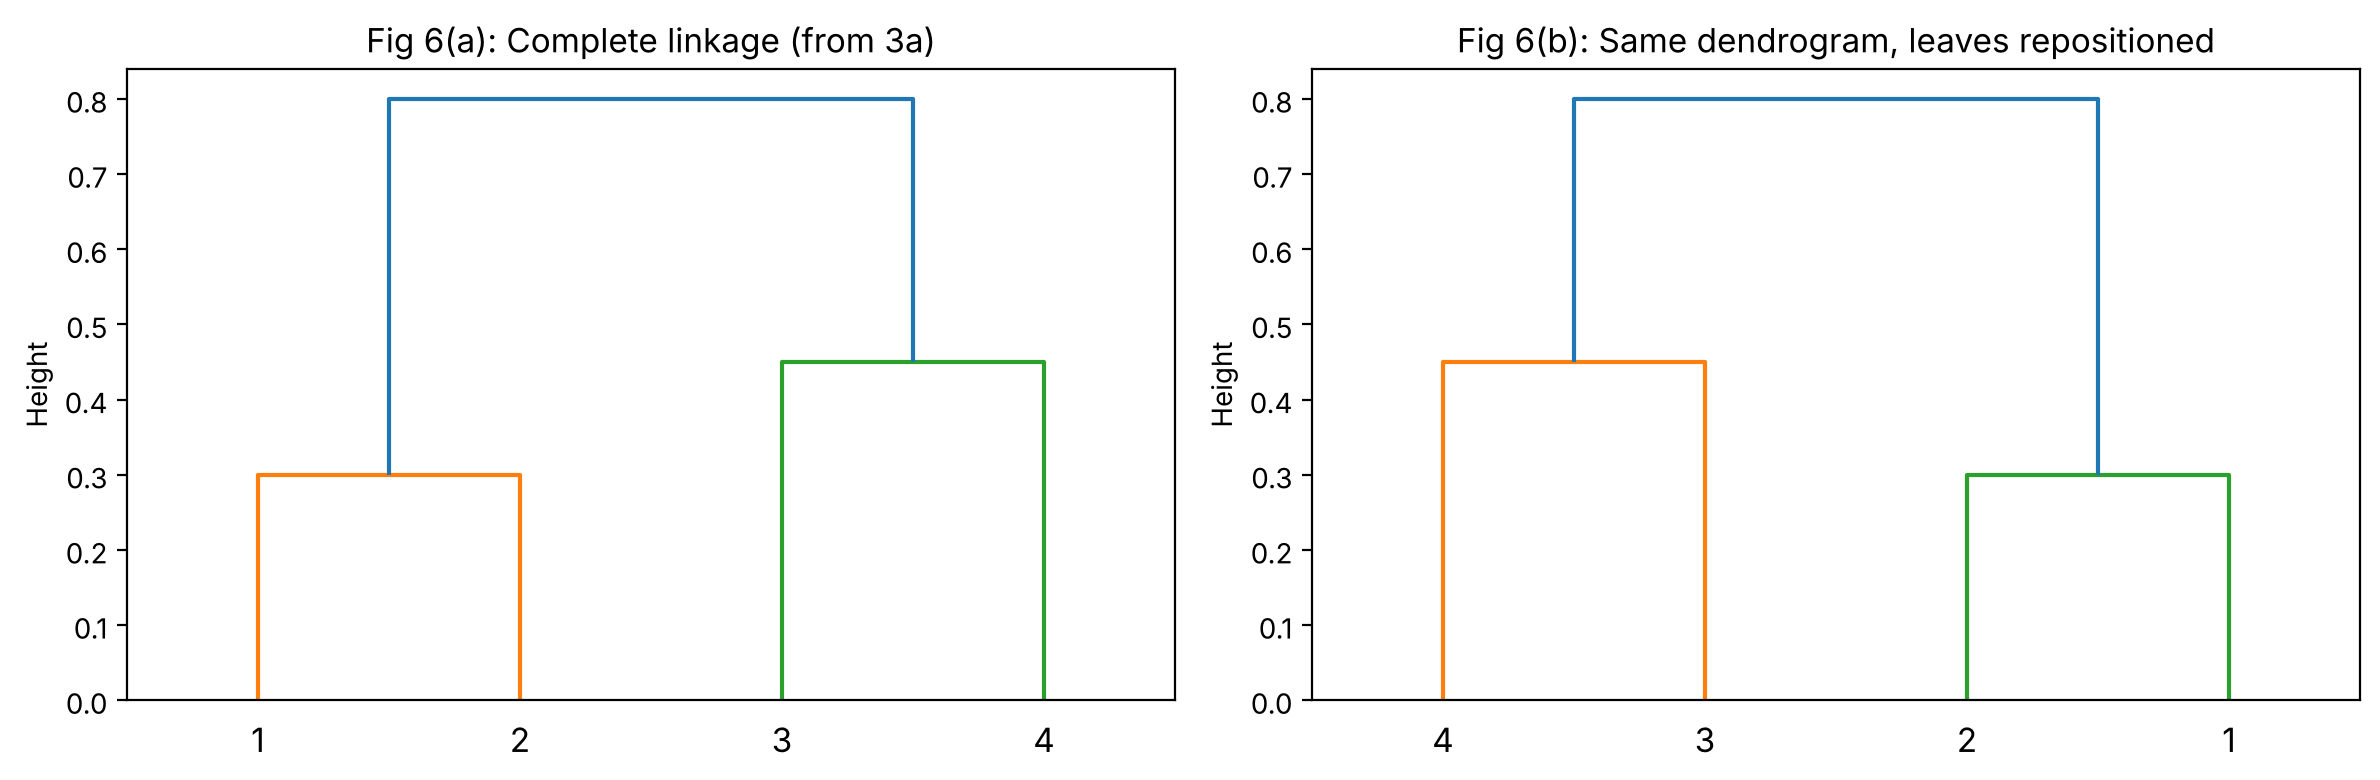

In [27]:
Z_swapped = Z_complete.copy()
Z_swapped[:, [0, 1]] = Z_swapped[:, [1, 0]]     # swap left/right child at every fusion

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dendrogram(Z_complete, labels=[1, 2, 3, 4], ax=axes[0]); axes[0].set_title("Fig 6(a): Complete linkage (from 3a)")
dendrogram(Z_swapped, labels=[1, 2, 3, 4], ax=axes[1]); axes[1].set_title("Fig 6(b): Same dendrogram, leaves repositioned")
for ax in axes: ax.set_ylabel("Height")
plt.tight_layout(); plt.show()

## References
1. Anuran Calls (MFCCs) Data Set, UCI Machine Learning Repository: https://archive.ics.uci.edu/ml/datasets/Anuran+Calls+%28MFCCs%29
2. M. S. Sorower, *A Literature Survey on Algorithms for Multi-label Learning*, Oregon State University, 2010.
3. scikit-learn documentation — `SVC`, `LinearSVC`, `OneVsRestClassifier`, `GridSearchCV`, `KMeans`, `silhouette_score`, multi-label metrics: https://scikit-learn.org/stable/
4. imbalanced-learn documentation — `SMOTE` and `imblearn.pipeline.Pipeline`: https://imbalanced-learn.org/stable/
5. N. V. Chawla et al., *SMOTE: Synthetic Minority Over-sampling Technique*, JAIR, 2002.
6. J. Read, B. Pfahringer, G. Holmes, E. Frank, *Classifier Chains for Multi-label Classification*, Machine Learning, 2011.
7. G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning*, 2nd ed., Chapter 12.
8. SciPy documentation — `scipy.cluster.hierarchy.linkage`, `dendrogram`, `fcluster`.